# 🚮 Industrial Waste Classification — Cross-Dataset Generalization (fixed pipeline)

**Question:** if a model is trained on waste images from *one* source (TrashBox, WaRP-C, RealWaste or SortWaste), how well does it work on the *other three* sources it has never seen?

**What changed compared with the old notebook**
1. Every source gets a **fresh pretrained model** (the old Step 8 kept fine-tuning one model on all datasets, so later "unseen" datasets were not unseen).
2. **Two protocols**: `native_3class` (cardboard / metal / plastic, original images only — the clean main result) and `supplemented_5class` (adds glass/paper from an external Kaggle set — secondary, because those classes come from a different source).
3. **Every function is defined before it is used** (`stratified_test_paths`, `evaluate_pair`, `training_summary` were missing before).
4. Class-balanced sampling in every split (the old pilot sampled the first N sorted images, which gave single-class test sets and macro-F1 = 0.2).
5. Multiple seeds, bootstrap confidence intervals, per-class recall, checkpoints saved to Drive (safe against Colab disconnects).
6. A `smoke` mode to test the whole notebook in a few minutes before the long `full` run.

**How to run (simple):**
1. `Runtime → Change runtime type → T4 GPU`.
2. Keep `RUN_MODE = "smoke"` in the next cell and run **all** cells (`Runtime → Run all`). It must finish with no red error. Numbers from smoke mode are meaningless — it only tests the pipeline.
3. Change `RUN_MODE = "full"`, then `Runtime → Restart session and run all`. Results and checkpoints are saved to your Google Drive.

## ⚙️ Step 0 — Settings (the only cell you edit)

In [ ]:
# ═══════════ EDIT ONLY THIS CELL ═══════════
RUN_MODE = "full"                  # "smoke" = quick pipeline test | "full" = real experiment
RUN_MODELS = ["MobileNetV3Large"]   # others available: "ResNet50", "EfficientNetB0", "ConvNeXtTiny"
ROBUSTNESS_SOURCE = "TrashBox"      # model trained on this dataset is used for robustness, ablation, Grad-CAM
DRIVE_DATA_PATH = None              # optional: exact Drive path of the zip OR the processed_data folder
RESUME_FROM_CHECKPOINTS = True      # reuse saved checkpoints if Colab disconnects mid-run
# ═══════════════════════════════════════════

PRESETS = {
    "smoke": dict(MAX_TRAIN_PER_CLASS=24, MAX_VAL_PER_CLASS=16, MAX_TEST_PER_CLASS=24,
                  MAX_EPOCHS=1, PATIENCE=1, SEEDS=[42], N_BOOTSTRAP=100,
                  ROB_PER_CLASS=8, CAM_POOL_PER_CLASS=15),
    "full":  dict(MAX_TRAIN_PER_CLASS=2000, MAX_VAL_PER_CLASS=None, MAX_TEST_PER_CLASS=None,
                  MAX_EPOCHS=5, PATIENCE=2, SEEDS=[42, 43, 44], N_BOOTSTRAP=1000,
                  ROB_PER_CLASS=150, CAM_POOL_PER_CLASS=100),
}
assert RUN_MODE in PRESETS, "RUN_MODE must be 'smoke' or 'full'"
_cfg = PRESETS[RUN_MODE]
MAX_TRAIN_PER_CLASS = _cfg["MAX_TRAIN_PER_CLASS"]   # None = use every training image
MAX_VAL_PER_CLASS = _cfg["MAX_VAL_PER_CLASS"]
MAX_TEST_PER_CLASS = _cfg["MAX_TEST_PER_CLASS"]
MAX_EPOCHS = _cfg["MAX_EPOCHS"]
PATIENCE = _cfg["PATIENCE"]
SEEDS = _cfg["SEEDS"]
N_BOOTSTRAP = _cfg["N_BOOTSTRAP"]
ROB_PER_CLASS = _cfg["ROB_PER_CLASS"]
CAM_POOL_PER_CLASS = _cfg["CAM_POOL_PER_CLASS"]

if RUN_MODE == "smoke":
    print("=" * 78)
    print("SMOKE MODE: tiny subsets, 1 epoch. This only checks that the pipeline runs.")
    print("DO NOT report any number from this run. Set RUN_MODE = 'full' for real results.")
    print("=" * 78)
else:
    print(f"FULL MODE: up to {MAX_TRAIN_PER_CLASS} train images/class, {MAX_EPOCHS} epochs, seeds {SEEDS}.")

FULL MODE: up to 2000 train images/class, 5 epochs, seeds [42, 43, 44].


## 📦 Step 1 — Imports, constants, GPU check

In [ ]:
from __future__ import annotations

import copy, hashlib, json, os, platform, random, shutil, subprocess, sys, time, zipfile
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
import torchvision
from IPython.display import display
from PIL import Image, ImageDraw, ImageEnhance, ImageFilter, ImageOps
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from torchvision.transforms import InterpolationMode
from tqdm.auto import tqdm

CLASS_NAMES = ["cardboard", "glass", "metal", "paper", "plastic"]
CORE_CLASSES = ["cardboard", "metal", "plastic"]          # present in ALL four original datasets
DATASETS = ["TrashBox", "WaRP-C", "RealWaste", "SortWaste"]
# 'study' folders = original images + external glass/paper where a dataset lacked them
STUDY_FOLDER = {"TrashBox": "TrashBox", "WaRP-C": "Warp-C-Supplemented",
                "RealWaste": "RealWaste", "SortWaste": "SortWaste-Supplemented"}
NATIVE_FOLDER = {"TrashBox": "TrashBox", "WaRP-C": "Warp-C",
                 "RealWaste": "RealWaste", "SortWaste": "SortWaste"}
REQUIRED_FOLDERS = sorted(set(STUDY_FOLDER.values()) | set(NATIVE_FOLDER.values()))
PROTOCOLS = {"native_3class": CORE_CLASSES, "supplemented_5class": CLASS_NAMES}

assert ROBUSTNESS_SOURCE in DATASETS, f"ROBUSTNESS_SOURCE must be one of {DATASETS}"
MODEL_NAMES_ALL = ["ResNet50", "EfficientNetB0", "MobileNetV3Large", "ConvNeXtTiny"]
assert all(m in MODEL_NAMES_ALL for m in RUN_MODELS), f"RUN_MODELS must be from {MODEL_NAMES_ALL}"

IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = min(4, os.cpu_count() or 2)
SEED_DEFAULT = 42

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    msg = "No GPU found. Use Runtime > Change runtime type > T4 GPU, then restart."
    if RUN_MODE == "full":
        raise RuntimeError(msg)
    print("WARNING:", msg, "(smoke mode will still run, slowly)")

def seed_everything(seed=SEED_DEFAULT):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()
print(f"torch={torch.__version__} torchvision={torchvision.__version__} sklearn={sklearn.__version__} workers={NUM_WORKERS}")

GPU: Tesla T4
torch=2.11.0+cu130 torchvision=0.26.0+cu130 sklearn=1.6.1 workers=2


## 📁 Step 2 — Find the data in Google Drive and copy it to fast local disk
The notebook accepts **either** `industrial_waste_processed_data.zip` **or** a plain `processed_data` folder in your Drive
(root of *My Drive* or inside *Colab Notebooks*). A zip is much faster (a folder with ~118,000 images is copied file by file).
If your path is different, set `DRIVE_DATA_PATH` in the settings cell.

In [ ]:
IN_COLAB = False
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    pass

DRIVE_ROOT = Path("/content/drive/MyDrive")
if IN_COLAB:
    drive.mount("/content/drive")

WORKSPACE = Path("/content/industrial_waste") if IN_COLAB else Path.cwd() / "industrial_waste_workspace"
WORKSPACE.mkdir(parents=True, exist_ok=True)

def has_all_folders(path: Path) -> bool:
    return path.is_dir() and all((path / name).is_dir() for name in REQUIRED_FOLDERS)

def find_data_root(base: Path, max_depth: int = 3):
    """Return the folder that directly contains TrashBox, Warp-C, ... (searching a few levels down)."""
    base = Path(base)
    if has_all_folders(base):
        return base
    if max_depth == 0 or not base.is_dir():
        return None
    for child in sorted(base.iterdir()):
        if child.is_dir():
            found = find_data_root(child, max_depth - 1)
            if found is not None:
                return found
    return None

def prepare_data() -> Path:
    local = find_data_root(WORKSPACE, 3)
    if local is not None:
        print("Data already on local disk:", local)
        return local

    candidates = []
    if DRIVE_DATA_PATH:
        candidates.append(Path(DRIVE_DATA_PATH))
    for base in (DRIVE_ROOT, DRIVE_ROOT / "Colab Notebooks"):
        candidates += [base / "industrial_waste_processed_data.zip", base / "processed_data.zip",
                       base / "processed_data", base / "industrial_waste" / "processed_data"]
    if DRIVE_ROOT.is_dir():
        for item in sorted(DRIVE_ROOT.iterdir()):
            if any(key in item.name.lower() for key in ("processed", "waste")):
                candidates.append(item)

    for cand in candidates:
        if cand.is_file() and cand.suffix.lower() == ".zip":
            print("Found zip:", cand, "- extracting (a few minutes)...")
            target = WORKSPACE / "_unzipped"
            with zipfile.ZipFile(cand) as archive:
                archive.extractall(target)
            root = find_data_root(target, 3)
            if root is not None:
                return root
            print("  zip did not contain the expected folders, trying next candidate")
        elif cand.is_dir():
            root = find_data_root(cand, 2)
            if root is not None:
                dest = WORKSPACE / "processed_data"
                dest.mkdir(parents=True, exist_ok=True)
                print("Found folder:", root, "- copying to local disk (can take 15-40 min for ~118k files)...")
                started = time.time()
                subprocess.run(["cp", "-r", f"{root}/.", str(dest)], check=True)
                print(f"Copy finished in {(time.time() - started) / 60:.1f} min")
                return dest

    listing = sorted(p.name for p in DRIVE_ROOT.iterdir()) if DRIVE_ROOT.is_dir() else "(Drive not mounted)"
    raise FileNotFoundError(
        "Could not find the dataset in Google Drive.\n"
        f"Need a zip or a folder that contains: {REQUIRED_FOLDERS}\n"
        f"Top level of My Drive currently has: {listing}\n"
        "Fix: upload it, or set DRIVE_DATA_PATH in the settings cell to its exact path."
    )

DATA_ROOT = prepare_data()
native_roots = {name: DATA_ROOT / NATIVE_FOLDER[name] for name in DATASETS}
study_roots = {name: DATA_ROOT / STUDY_FOLDER[name] for name in DATASETS}

RESULTS_DIR = (DRIVE_ROOT / "industrial_waste_results" / RUN_MODE) if (IN_COLAB and DRIVE_ROOT.is_dir()) \
    else WORKSPACE / "results" / RUN_MODE
CKPT_DIR = RESULTS_DIR / "checkpoints"
CKPT_DIR.mkdir(parents=True, exist_ok=True)
print("Data root   :", DATA_ROOT)
print("Results dir :", RESULTS_DIR)

Mounted at /content/drive
Found zip: /content/drive/MyDrive/Colab Notebooks/industrial_waste_processed_data.zip - extracting (a few minutes)...
Data root   : /content/industrial_waste/_unzipped/processed_data
Results dir : /content/drive/MyDrive/industrial_waste_results/full


## 📊 Step 3 — Inventory and gap analysis
Counts images per class in every original dataset, shows which classes are missing natively
(WaRP-C has no *paper*; SortWaste has no *glass* or *paper*), and checks the supplemented copies are complete.

In [ ]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
SPLITS = ("train", "val", "test")
_LIST_CACHE = {}

def label_of(path: Path) -> str:
    return path.parent.name.strip().lower()

def list_images(folder):
    folder = Path(folder)
    if folder not in _LIST_CACHE:
        _LIST_CACHE[folder] = sorted(
            p for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
    return _LIST_CACHE[folder]

def inventory(roots):
    rows = []
    for dataset, root in roots.items():
        for split in SPLITS:
            split_root = root / split
            if not split_root.is_dir():
                raise FileNotFoundError(f"Missing split folder: {split_root}")
            counts = Counter(label_of(p) for p in list_images(split_root))
            unexpected = set(counts) - set(CLASS_NAMES)
            if unexpected:
                print(f"WARNING {dataset}/{split}: unexpected class folders {sorted(unexpected)} (ignored)")
            rows.append({"dataset": dataset, "split": split, "images": sum(counts.values()),
                         **{c: counts.get(c, 0) for c in CLASS_NAMES}})
    return pd.DataFrame(rows)

print("Counting images (a minute for the large SortWaste folders)...")
native_inventory = inventory(native_roots)
study_inventory = inventory(study_roots)
print("\nORIGINAL datasets:")
display(native_inventory)

presence = native_inventory.groupby("dataset")[CLASS_NAMES].sum().gt(0).reindex(DATASETS)
missing_native = {d: [c for c in CLASS_NAMES if not presence.loc[d, c]] for d in DATASETS}
print("Classes missing in the ORIGINAL sources:", {k: v for k, v in missing_native.items() if v})

print("\nSTUDY datasets (original + external glass/paper where missing):")
display(study_inventory)
for dataset in DATASETS:
    for split in SPLITS:
        row = study_inventory.query("dataset == @dataset and split == @split").iloc[0]
        absent = [c for c in CLASS_NAMES if row[c] == 0]
        if absent:
            raise ValueError(f"{dataset}/{split} still misses classes {absent}")

same_core = (native_inventory.set_index(["dataset", "split"])[CORE_CLASSES]
             == study_inventory.set_index(["dataset", "split"])[CORE_CLASSES]).all().all()
print("\nCore classes (cardboard/metal/plastic) identical in original and study folders:", bool(same_core))
if not same_core:
    print("WARNING: study folders changed core-class images; the 3-class protocol uses the STUDY folders.")

Counting images (a minute for the large SortWaste folders)...

ORIGINAL datasets:


,dataset,split,images,cardboard,glass,metal,paper,plastic
0,TrashBox,train,10309,1929,2022,2068,2155,2135
1,TrashBox,val,1283,241,252,257,268,265
2,TrashBox,test,1299,242,254,261,271,271
3,WaRP-C,train,7457,553,381,477,0,6046
4,WaRP-C,val,1310,97,66,83,0,1064
5,WaRP-C,test,1551,162,86,98,0,1205
6,RealWaste,train,2163,322,294,553,350,644
7,RealWaste,val,463,69,63,118,75,138
8,RealWaste,test,466,70,63,119,75,139
9,SortWaste,train,61842,15173,0,945,0,45724


Classes missing in the ORIGINAL sources: {'WaRP-C': ['paper'], 'SortWaste': ['glass', 'paper']}

STUDY datasets (original + external glass/paper where missing):


,dataset,split,images,cardboard,glass,metal,paper,plastic
0,TrashBox,train,10309,1929,2022,2068,2155,2135
1,TrashBox,val,1283,241,252,257,268,265
2,TrashBox,test,1299,242,254,261,271,271
3,WaRP-C,train,8090,553,381,477,633,6046
4,WaRP-C,val,1445,97,66,83,135,1064
5,WaRP-C,test,1688,162,86,98,137,1205
6,RealWaste,train,2163,322,294,553,350,644
7,RealWaste,val,463,69,63,118,75,138
8,RealWaste,test,466,70,63,119,75,139
9,SortWaste,train,64079,15173,1605,945,632,45724



Core classes (cardboard/metal/plastic) identical in original and study folders: True


## 🔍 Step 4 — Exact-duplicate and train/test leakage audit
SHA-256 of every image file. Training images that also appear in *any* test set are removed, exact duplicates inside a split are removed,
and validation images that appear in any test or training set are removed. The test sets themselves are never touched.
(This catches identical files only, not near-duplicate video frames — see the limitations at the end.)

In [ ]:
def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

all_paths = sorted({p for root in study_roots.values() for split in SPLITS for p in list_images(root / split)})
print(f"Hashing {len(all_paths):,} files...")
started = time.time()
HASH_WORKERS = min(8, (os.cpu_count() or 1) * 2)
with ThreadPoolExecutor(max_workers=HASH_WORKERS) as pool:
    path_hashes = dict(zip(all_paths, pool.map(sha256_file, all_paths)))
print(f"Done in {(time.time() - started) / 60:.1f} min")

test_hashes = {path_hashes[p] for root in study_roots.values() for p in list_images(root / "test")}
train_hashes_all = {path_hashes[p] for root in study_roots.values() for p in list_images(root / "train")}

filtered_paths = {}
leak_rows = []
for dataset, root in study_roots.items():
    split_paths = {s: list_images(root / s) for s in SPLITS}
    seen, kept_train, rm_test, rm_dup = set(), [], 0, 0
    for p in split_paths["train"]:
        h = path_hashes[p]
        if h in test_hashes:
            rm_test += 1
        elif h in seen:
            rm_dup += 1
        else:
            kept_train.append(p)
            seen.add(h)
    seen_val, kept_val, rv_test, rv_train, rv_dup = set(), [], 0, 0, 0
    for p in split_paths["val"]:
        h = path_hashes[p]
        if h in test_hashes:
            rv_test += 1
        elif h in train_hashes_all:
            rv_train += 1
        elif h in seen_val:
            rv_dup += 1
        else:
            kept_val.append(p)
            seen_val.add(h)
    filtered_paths[(dataset, "train")] = kept_train
    filtered_paths[(dataset, "val")] = kept_val
    filtered_paths[(dataset, "test")] = split_paths["test"]
    leak_rows.append({"dataset": dataset, "train_before": len(split_paths["train"]),
                      "train_removed_overlap_with_test": rm_test, "train_removed_duplicates": rm_dup,
                      "train_after": len(kept_train), "val_before": len(split_paths["val"]),
                      "val_removed_overlap_with_test": rv_test, "val_removed_overlap_with_train": rv_train,
                      "val_removed_duplicates": rv_dup, "val_after": len(kept_val)})
leakage_audit = pd.DataFrame(leak_rows)
display(leakage_audit)

# sanity check: after filtering, no train/val image shares a hash with any test image
bad = sum(path_hashes[p] in test_hashes for (d, s), ps in filtered_paths.items() if s != "test" for p in ps)
print("Train/val images sharing a hash with a test image after filtering:", bad)
assert bad == 0

Hashing 117,929 files...
Done in 0.3 min


,dataset,train_before,train_removed_overlap_with_test,train_removed_duplicates,train_after,val_before,val_removed_overlap_with_test,val_removed_overlap_with_train,val_removed_duplicates,val_after
0,TrashBox,10309,0,254,10055,1283,9,0,4,1270
1,WaRP-C,8090,0,0,8090,1445,0,0,0,1445
2,RealWaste,2163,0,0,2163,463,0,0,0,463
3,SortWaste,64079,0,21,64058,13544,0,0,0,13544


Train/val images sharing a hash with a test image after filtering: 0


## 🖼️ Step 5 — Dataset class, augmentation, balanced sampling
`sample_per_class` takes the **same number of images from every class** (random, seeded). The old pilot took the first N sorted files, which could give a test set with a single class.

In [ ]:
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.80, 1.0), interpolation=InterpolationMode.BILINEAR),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15, interpolation=InterpolationMode.BILINEAR),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.15),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

def load_rgb(path):
    with Image.open(path) as opened:
        try:
            opened.draft("RGB", (IMAGE_SIZE * 2, IMAGE_SIZE * 2))   # faster decoding of big JPEGs
        except Exception:
            pass
        return ImageOps.exif_transpose(opened).convert("RGB")

class WasteDataset(Dataset):
    def __init__(self, paths, classes, transform=None):
        self.classes = list(classes)
        class_to_idx = {c: i for i, c in enumerate(self.classes)}
        self.samples = [(p, class_to_idx[label_of(p)]) for p in paths if label_of(p) in class_to_idx]
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, target = self.samples[index]
        image = load_rgb(path)
        if self.transform is not None:
            image = self.transform(image)
        return image, target

def sample_per_class(paths, classes, limit, seed):
    """Balanced, seeded subsample. limit=None keeps everything (only the requested classes)."""
    grouped = defaultdict(list)
    for p in paths:
        label = label_of(p)
        if label in classes:
            grouped[label].append(p)
    rng = random.Random(seed)
    chosen = []
    for label in classes:
        candidates = sorted(grouped[label])
        if limit is not None and len(candidates) > limit:
            rng.shuffle(candidates)
            candidates = candidates[:limit]
        chosen.extend(candidates)
    return sorted(chosen)

def _worker_init(worker_id):
    seed = torch.initial_seed() % (2 ** 32)
    random.seed(seed)
    np.random.seed(seed)

def make_loader(dataset, shuffle=False, seed=SEED_DEFAULT, persistent=False):
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"), persistent_workers=(persistent and NUM_WORKERS > 0),
        generator=generator if shuffle else None, worker_init_fn=_worker_init)

# what the training sets will look like (per protocol, after the per-class cap)
rows = []
for protocol, classes in PROTOCOLS.items():
    for dataset in DATASETS:
        chosen = sample_per_class(filtered_paths[(dataset, "train")], classes, MAX_TRAIN_PER_CLASS, SEEDS[0])
        counts = Counter(label_of(p) for p in chosen)
        rows.append({"protocol": protocol, "dataset": dataset, "train_images": len(chosen),
                     **{c: counts.get(c, 0) for c in classes}})
train_table = pd.DataFrame(rows).fillna(0)
for _c in CLASS_NAMES:
    train_table[_c] = train_table[_c].astype(int)
display(train_table)

,protocol,dataset,train_images,cardboard,metal,plastic,glass,paper
0,native_3class,TrashBox,5873,1873,2000,2000,0,0
1,native_3class,WaRP-C,3030,553,477,2000,0,0
2,native_3class,RealWaste,1519,322,553,644,0,0
3,native_3class,SortWaste,4945,2000,945,2000,0,0
4,supplemented_5class,TrashBox,9725,1873,2000,2000,1852,2000
5,supplemented_5class,WaRP-C,4044,553,477,2000,381,633
6,supplemented_5class,RealWaste,2163,322,553,644,294,350
7,supplemented_5class,SortWaste,7182,2000,945,2000,1605,632


## 🧠 Step 6 — Models, training loop, evaluation helpers
* Every source dataset trains a **fresh ImageNet-pretrained model**; the best epoch is chosen with macro-F1 on the **source** validation split only (the target datasets are never looked at).
* Class-weighted loss, AdamW, LR schedule, early stopping, mixed precision on GPU.
* Checkpoints are saved to Drive; if Colab disconnects, re-run and finished models are loaded instead of retrained.
* Metrics: accuracy, balanced accuracy, macro-F1 with a bootstrap 95% interval, per-class recall, confusion matrix.

In [ ]:
def build_model(model_name, num_classes, pretrained=True):
    if model_name == "ResNet50":
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT if pretrained else None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif model_name == "EfficientNetB0":
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT if pretrained else None)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, num_classes)
    elif model_name == "MobileNetV3Large":
        model = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.DEFAULT if pretrained else None)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, num_classes)
    elif model_name == "ConvNeXtTiny":
        model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.DEFAULT if pretrained else None)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, num_classes)
    else:
        raise ValueError(f"Unknown model: {model_name}")
    return model

def get_head(model, model_name):
    return model.fc if model_name == "ResNet50" else model.classifier

def amp_ctx():
    return torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=(DEVICE.type == "cuda"))

def class_weights(dataset, num_classes):
    counts = np.bincount([t for _, t in dataset.samples], minlength=num_classes).astype(np.float64)
    if np.any(counts == 0):
        missing = [dataset.classes[i] for i, c in enumerate(counts) if c == 0]
        raise ValueError(f"Training set has no images for classes: {missing}")
    weights = counts.sum() / (num_classes * counts)
    weights /= weights.mean()
    return torch.tensor(weights, dtype=torch.float32), counts.astype(int)

# ---------- metrics (numpy, so bootstrapping is fast) ----------
def confusion(y_true, y_pred, k):
    y_true = np.asarray(y_true, dtype=np.int64)
    y_pred = np.asarray(y_pred, dtype=np.int64)
    return np.bincount(y_true * k + y_pred, minlength=k * k).reshape(k, k)

def macro_f1_from_cm(cm):
    k = cm.shape[0]
    tp = np.diag(cm).astype(float)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    denom = 2 * tp + fp + fn
    f1 = np.divide(2 * tp, denom, out=np.zeros(k), where=denom > 0)
    return float(f1.mean())

def bootstrap_ci(y_true, y_pred, k, n_boot, seed):
    y_true = np.asarray(y_true, dtype=np.int64)
    y_pred = np.asarray(y_pred, dtype=np.int64)
    rng = np.random.default_rng(seed)
    n = len(y_true)
    scores = [macro_f1_from_cm(confusion(y_true[idx], y_pred[idx], k))
              for idx in (rng.integers(0, n, n) for _ in range(n_boot))]
    return float(np.percentile(scores, 2.5)), float(np.percentile(scores, 97.5))

def predict(model, loader):
    model.eval()
    ys, ps = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            with amp_ctx():
                logits = model(images)
            ps.append(logits.argmax(dim=1).cpu().numpy())
            ys.append(labels.numpy())
    if not ys:
        raise ValueError("Empty loader: no images to evaluate.")
    return np.concatenate(ys).astype(np.int64), np.concatenate(ps).astype(np.int64)

def metrics_from_predictions(y_true, y_pred, classes, seed):
    k = len(classes)
    cm = confusion(y_true, y_pred, k)
    support = cm.sum(axis=1)
    recall = np.divide(np.diag(cm), support, out=np.zeros(k), where=support > 0)
    low, high = bootstrap_ci(y_true, y_pred, k, N_BOOTSTRAP, seed)
    row = {"n_test": int(len(y_true)),
           "accuracy": float((np.asarray(y_true) == np.asarray(y_pred)).mean()),
           "balanced_accuracy": float(recall[support > 0].mean()),
           "macro_f1": macro_f1_from_cm(cm), "macro_f1_ci_low": low, "macro_f1_ci_high": high}
    for i, c in enumerate(classes):
        row[f"recall_{c}"] = float(recall[i])
    return row, cm

def evaluate_on(model, target, classes, seed):
    """Evaluate a trained model on the TEST split of `target` (balanced cap only in smoke mode)."""
    paths = sample_per_class(filtered_paths[(target, "test")], classes, MAX_TEST_PER_CLASS, seed)
    data = WasteDataset(paths, classes, eval_transform)
    y_true, y_pred = predict(model, make_loader(data))
    return metrics_from_predictions(y_true, y_pred, classes, seed)

# ---------- training ----------
def set_train_mode(model, freeze):
    model.train()
    if freeze:   # a frozen backbone must not update its BatchNorm statistics either
        for module in model.modules():
            if isinstance(module, (nn.BatchNorm1d, nn.BatchNorm2d)):
                module.eval()

def train_model(model_name, source, classes, seed, use_weights=True, use_aug=True, freeze=False, tag="main"):
    seed_everything(seed)
    train_paths = sample_per_class(filtered_paths[(source, "train")], classes, MAX_TRAIN_PER_CLASS, seed)
    val_paths = sample_per_class(filtered_paths[(source, "val")], classes, MAX_VAL_PER_CLASS, 1234)
    train_data = WasteDataset(train_paths, classes, train_transform if use_aug else eval_transform)
    val_data = WasteDataset(val_paths, classes, eval_transform)
    if len(train_data) == 0 or len(val_data) == 0:
        raise ValueError(f"Empty train/val set for {source} with classes {classes}")
    k = len(classes)
    weight_tensor, train_counts = class_weights(train_data, k)

    model = build_model(model_name, k, pretrained=True).to(DEVICE)
    head = get_head(model, model_name)
    if freeze:
        for p in model.parameters():
            p.requires_grad = False
        for p in head.parameters():
            p.requires_grad = True
    head_params = [p for p in head.parameters() if p.requires_grad]
    head_ids = {id(p) for p in head_params}
    backbone_params = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
    groups = [{"params": head_params, "lr": 1e-3}]
    if backbone_params:
        groups.insert(0, {"params": backbone_params, "lr": 1e-4})
    optimizer = torch.optim.AdamW(groups, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=1)
    criterion = nn.CrossEntropyLoss(weight=weight_tensor.to(DEVICE) if use_weights else None)
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))
    train_loader = make_loader(train_data, shuffle=True, seed=seed, persistent=True)
    val_loader = make_loader(val_data)

    best_score, best_epoch, best_state, stale = -1.0, 0, None, 0
    history, started = [], time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        set_train_mode(model, freeze)
        total_loss, total_n = 0.0, 0
        for images, labels in tqdm(train_loader, desc=f"{tag}|{model_name}|{source}|ep{epoch}", leave=False):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with amp_ctx():
                loss = criterion(model(images), labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            total_loss += loss.item() * labels.size(0)
            total_n += labels.size(0)
        y_val, p_val = predict(model, val_loader)
        score = macro_f1_from_cm(confusion(y_val, p_val, k))
        scheduler.step(score)
        history.append({"epoch": epoch, "train_loss": total_loss / max(total_n, 1),
                        "val_macro_f1": score, "val_accuracy": float((y_val == p_val).mean())})
        print(f"  {model_name} | {source} | epoch {epoch}: loss={history[-1]['train_loss']:.4f} val macro-F1={score:.4f}")
        if score > best_score:
            best_score, best_epoch, stale = score, epoch, 0
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        else:
            stale += 1
            if stale >= PATIENCE:
                break
    model.load_state_dict(best_state)
    record = {"tag": tag, "model": model_name, "source": source, "seed": int(seed),
              "classes": list(classes), "selected_epoch": int(best_epoch),
              "best_val_macro_f1": float(best_score), "training_seconds": float(time.time() - started),
              "train_images": len(train_data), "val_images": len(val_data),
              "train_class_counts": {c: int(train_counts[i]) for i, c in enumerate(classes)},
              "weighted_loss": bool(use_weights), "augmentation": bool(use_aug), "backbone_frozen": bool(freeze)}
    return model, record, history

_cfg_blob = json.dumps({"mode": RUN_MODE, "train": MAX_TRAIN_PER_CLASS, "val": MAX_VAL_PER_CLASS,
                        "epochs": MAX_EPOCHS, "size": IMAGE_SIZE, "batch": BATCH_SIZE}, sort_keys=True)
CFG_TAG = hashlib.md5(_cfg_blob.encode()).hexdigest()[:8]

def get_or_train(model_name, source, protocol, seed, tag="main", **kwargs):
    """Load a finished checkpoint (resume) or train a fresh model. Returns (model, record, history)."""
    classes = PROTOCOLS[protocol]
    path = CKPT_DIR / f"{CFG_TAG}_{protocol}_{model_name}_{source}_s{seed}_{tag}.pt"
    if RESUME_FROM_CHECKPOINTS and path.is_file():
        blob = torch.load(path, map_location="cpu", weights_only=True)
        model = build_model(model_name, len(classes), pretrained=False)
        model.load_state_dict(blob["state"])
        print(f"  loaded checkpoint {path.name}")
        return model.to(DEVICE), blob["record"], blob["history"]
    model, record, history = train_model(model_name, source, classes, seed, tag=tag, **kwargs)
    torch.save({"state": {k: v.detach().cpu() for k, v in model.state_dict().items()},
                "record": record, "history": history}, path)
    return model, record, history

def model_from_state(model_name, classes, state):
    model = build_model(model_name, len(classes), pretrained=False)
    model.load_state_dict(state)
    return model.to(DEVICE).eval()

print("Training and evaluation helpers ready.")

Training and evaluation helpers ready.


## 🧪 Step 7 — Main experiment: train on one source, test on all four
For each protocol × model × seed × **source dataset**: train a fresh model, then evaluate it on the test split of **every** dataset.
The diagonal (train = test dataset) is the in-domain score; the off-diagonal cells are the true cross-dataset scores.
Progress is saved to Drive after every model.

In [ ]:
result_rows, confusions, STATES, train_records, train_histories = [], {}, {}, [], []
experiment_started = time.time()

for protocol, classes in PROTOCOLS.items():
    for model_name in RUN_MODELS:
        for seed in SEEDS:
            for source in DATASETS:
                print(f"\n=== {protocol} | {model_name} | seed {seed} | train on {source} ===")
                model, record, history = get_or_train(model_name, source, protocol, seed)
                train_records.append({**record, "protocol": protocol})
                train_histories.extend({**h, "protocol": protocol, "model": model_name,
                                        "source": source, "seed": seed} for h in history)
                model.eval()
                for target in DATASETS:
                    row, cm = evaluate_on(model, target, classes, seed=seed * 100 + DATASETS.index(target))
                    row.update({"run_mode": RUN_MODE, "protocol": protocol, "model": model_name, "seed": seed,
                                "train_dataset": source, "test_dataset": target,
                                "in_domain": source == target})
                    result_rows.append(row)
                    confusions[(protocol, model_name, seed, source, target)] = cm
                if seed == SEEDS[0]:
                    STATES[(protocol, model_name, source)] = {k: v.detach().cpu().clone()
                                                              for k, v in model.state_dict().items()}
                del model
                if DEVICE.type == "cuda":
                    torch.cuda.empty_cache()
                pd.DataFrame(result_rows).to_csv(RESULTS_DIR / "results_partial.csv", index=False)

results = pd.DataFrame(result_rows)
training_summary = pd.DataFrame(train_records)
print(f"\nAll models finished in {(time.time() - experiment_started) / 60:.1f} min")
display(training_summary[["protocol", "model", "source", "seed", "selected_epoch", "best_val_macro_f1",
                          "train_images", "training_seconds"]])


=== native_3class | MobileNetV3Large | seed 42 | train on TrashBox ===
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 144MB/s]


main|MobileNetV3Large|TrashBox|ep1:   0%|          | 0/184 [00:00<?, ?it/s]

  MobileNetV3Large | TrashBox | epoch 1: loss=0.3105 val macro-F1=0.9461


main|MobileNetV3Large|TrashBox|ep2:   0%|          | 0/184 [00:00<?, ?it/s]

...

main|MobileNetV3Large|SortWaste|ep2:   0%|          | 0/225 [00:00<?, ?it/s]

  MobileNetV3Large | SortWaste | epoch 2: loss=0.1689 val macro-F1=0.7463


main|MobileNetV3Large|SortWaste|ep3:   0%|          | 0/225 [00:00<?, ?it/s]

  MobileNetV3Large | SortWaste | epoch 3: loss=0.1252 val macro-F1=0.7515

All models finished in 81.9 min


,protocol,model,source,seed,selected_epoch,best_val_macro_f1,train_images,training_seconds
0,native_3class,MobileNetV3Large,TrashBox,42,3,0.975118,5873,215.829157
1,native_3class,MobileNetV3Large,WaRP-C,42,5,0.855241,3030,115.248246
2,native_3class,MobileNetV3Large,RealWaste,42,3,0.928514,1519,56.710360
3,native_3class,MobileNetV3Large,SortWaste,42,3,0.740934,4945,264.090782
4,native_3class,MobileNetV3Large,TrashBox,43,5,0.981668,5873,194.622151
5,native_3class,MobileNetV3Large,WaRP-C,43,4,0.884297,3030,110.814575
6,native_3class,MobileNetV3Large,RealWaste,43,2,0.901595,1519,45.080592
7,native_3class,MobileNetV3Large,SortWaste,43,2,0.742258,4945,213.755583
8,native_3class,MobileNetV3Large,TrashBox,44,5,0.985417,5873,195.119922
9,native_3class,MobileNetV3Large,WaRP-C,44,1,0.837882,3030,66.729763


## 📈 Step 8 — Cross-dataset results
* **Heatmaps:** rows = training dataset, columns = test dataset, value = macro-F1 (mean over seeds, ± std when several seeds).
* **Generalization gap** = in-domain macro-F1 minus the average macro-F1 on the three other datasets. Bigger gap = worse generalization.
* **Main result = `native_3class`.** `supplemented_5class` is secondary because its glass/paper images in WaRP-C and SortWaste come from a different source.

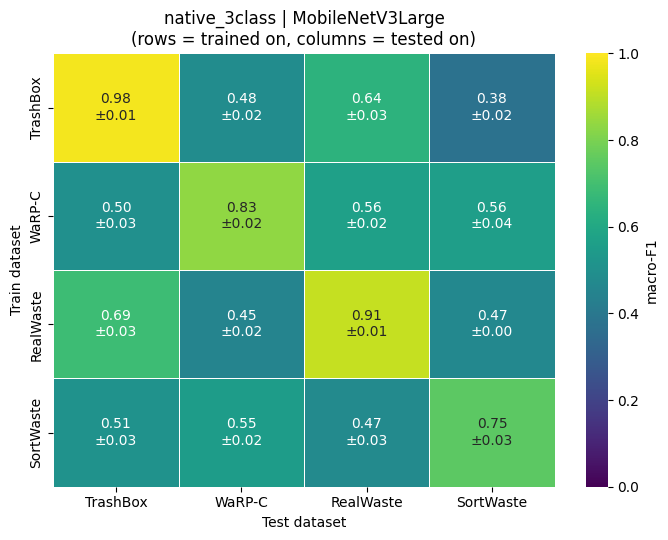

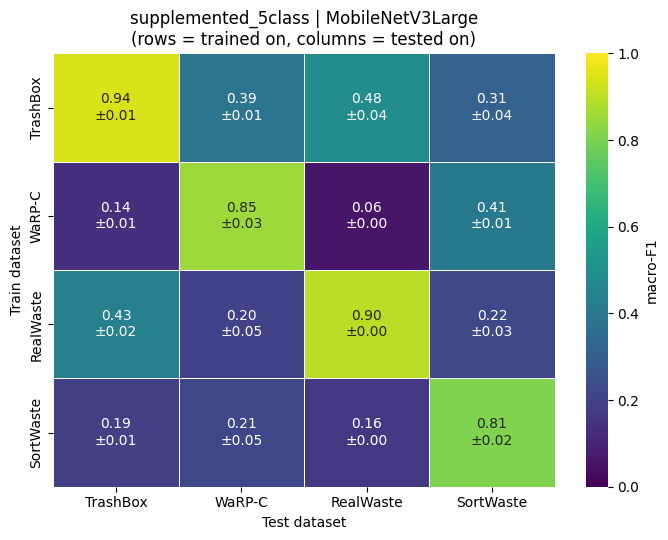

Generalization gap (in-domain minus average cross-dataset):


,protocol,model,train_dataset,in_domain_macro_f1,cross_dataset_macro_f1,generalization_gap
0,native_3class,MobileNetV3Large,RealWaste,0.912,0.535,0.377
1,native_3class,MobileNetV3Large,SortWaste,0.749,0.512,0.237
2,native_3class,MobileNetV3Large,TrashBox,0.981,0.499,0.482
3,native_3class,MobileNetV3Large,WaRP-C,0.833,0.539,0.294
4,supplemented_5class,MobileNetV3Large,RealWaste,0.897,0.281,0.616
5,supplemented_5class,MobileNetV3Large,SortWaste,0.806,0.188,0.617
6,supplemented_5class,MobileNetV3Large,TrashBox,0.944,0.392,0.552
7,supplemented_5class,MobileNetV3Large,WaRP-C,0.852,0.200,0.652


Average per-class RECALL on the other datasets (a value near 0 = that class collapses):


recall_cardboard  \
protocol            model            train_dataset                     
native_3class       MobileNetV3Large RealWaste                 0.666   
                                     SortWaste                 0.574   
                                     TrashBox                  0.374   
                                     WaRP-C                    0.452   
supplemented_5class MobileNetV3Large RealWaste                 0.494   
                                     SortWaste                 0.029   
                                     TrashBox                  0.201   
                                     WaRP-C                    0.179   

                                                    recall_metal  \
protocol            model            train_dataset                 
native_3class       MobileNetV3Large RealWaste             0.264   
                                     SortWaste             0.170   
                                     TrashBox              0.521   
                                     WaRP-C                0.413   
supplemented_5class MobileNetV3Large RealWaste             0.224   
                                     SortWaste             0.031   
                                     TrashBox              0.409   
                                     WaRP-C                0.110   

                                                    recall_plastic  \
protocol            model            train_dataset                   
native_3class       MobileNetV3Large RealWaste               0.715   
                                     SortWaste               0.859   
                                     TrashBox                0.736   
                                     WaRP-C                  0.829   
supplemented_5class MobileNetV3Large RealWaste               0.225   
                                     SortWaste               0.041   
                                     TrashBox                0.558   
                                     WaRP-C                  0.308   

                                                    recall_glass  recall_paper  
protocol            model            train_dataset                              
native_3class       MobileNetV3Large RealWaste               NaN           NaN  
                                     SortWaste               NaN           NaN  
                                     TrashBox                NaN           NaN  
                                     WaRP-C                  NaN           NaN  
supplemented_5class MobileNetV3Large RealWaste             0.579         0.410  
                                     SortWaste             0.776         0.889  
                                     TrashBox              0.571         0.695  
                                     WaRP-C                0.050         0.997

,protocol,model,seed,train_dataset,test_dataset,n_test,accuracy,balanced_accuracy,macro_f1,macro_f1_ci_low,macro_f1_ci_high
0,native_3class,MobileNetV3Large,42,TrashBox,TrashBox,774,0.974,0.975,0.974,0.963,0.985
1,native_3class,MobileNetV3Large,42,TrashBox,WaRP-C,1465,0.713,0.527,0.463,0.429,0.496
2,native_3class,MobileNetV3Large,42,TrashBox,RealWaste,328,0.610,0.621,0.607,0.548,0.657
3,native_3class,MobileNetV3Large,42,TrashBox,SortWaste,12618,0.719,0.427,0.386,0.371,0.401
4,native_3class,MobileNetV3Large,42,WaRP-C,TrashBox,774,0.500,0.500,0.485,0.451,0.523
...,...,...,...,...,...,...,...,...,...,...,...
91,supplemented_5class,MobileNetV3Large,44,RealWaste,SortWaste,13100,0.254,0.357,0.199,0.191,0.206
92,supplemented_5class,MobileNetV3Large,44,SortWaste,TrashBox,1299,0.326,0.324,0.197,0.182,0.212
93,supplemented_5class,MobileNetV3Large,44,SortWaste,WaRP-C,1688,0.295,0.424,0.268,0.240,0.295
94,supplemented_5class,MobileNetV3Large,44,SortWaste,RealWaste,466,0.258,0.339,0.164,0.141,0.185


In [ ]:
agg = (results.groupby(["protocol", "model", "train_dataset", "test_dataset"])["macro_f1"]
       .agg(["mean", "std"]).reset_index())

def save_fig(fig, name):
    fig.savefig(RESULTS_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

def plot_matrix(protocol, model_name):
    sub = agg[(agg.protocol == protocol) & (agg.model == model_name)]
    mean = sub.pivot(index="train_dataset", columns="test_dataset", values="mean").reindex(index=DATASETS, columns=DATASETS)
    std = sub.pivot(index="train_dataset", columns="test_dataset", values="std").reindex(index=DATASETS, columns=DATASETS)
    labels = np.empty(mean.shape, dtype=object)
    for i, r in enumerate(DATASETS):
        for j, c in enumerate(DATASETS):
            m, s = mean.loc[r, c], std.loc[r, c]
            labels[i, j] = f"{m:.2f}" if pd.isna(s) else f"{m:.2f}\n±{s:.2f}"
    fig, ax = plt.subplots(figsize=(7, 5.5))
    sns.heatmap(mean.astype(float), annot=labels, fmt="", cmap="viridis", vmin=0, vmax=1,
                linewidths=0.5, cbar_kws={"label": "macro-F1"}, ax=ax)
    ax.set_title(f"{protocol} | {model_name}\n(rows = trained on, columns = tested on)")
    ax.set_xlabel("Test dataset")
    ax.set_ylabel("Train dataset")
    plt.tight_layout()
    save_fig(fig, f"matrix_{protocol}_{model_name}")
    plt.show()

for protocol in PROTOCOLS:
    for model_name in RUN_MODELS:
        plot_matrix(protocol, model_name)

gap_rows = []
for (protocol, model_name, source), sub in agg.groupby(["protocol", "model", "train_dataset"]):
    in_dom = sub.loc[sub.test_dataset == source, "mean"].mean()
    off_dom = sub.loc[sub.test_dataset != source, "mean"].mean()
    gap_rows.append({"protocol": protocol, "model": model_name, "train_dataset": source,
                     "in_domain_macro_f1": in_dom, "cross_dataset_macro_f1": off_dom,
                     "generalization_gap": in_dom - off_dom})
gap_table = pd.DataFrame(gap_rows)
print("Generalization gap (in-domain minus average cross-dataset):")
display(gap_table.round(3))

recall_cols = [c for c in results.columns if c.startswith("recall_")]
per_class = results[~results.in_domain].groupby(["protocol", "model", "train_dataset"])[recall_cols].mean()
print("Average per-class RECALL on the other datasets (a value near 0 = that class collapses):")
display(per_class.round(3))
display(results[["protocol", "model", "seed", "train_dataset", "test_dataset", "n_test", "accuracy",
                 "balanced_accuracy", "macro_f1", "macro_f1_ci_low", "macro_f1_ci_high"]].round(3))

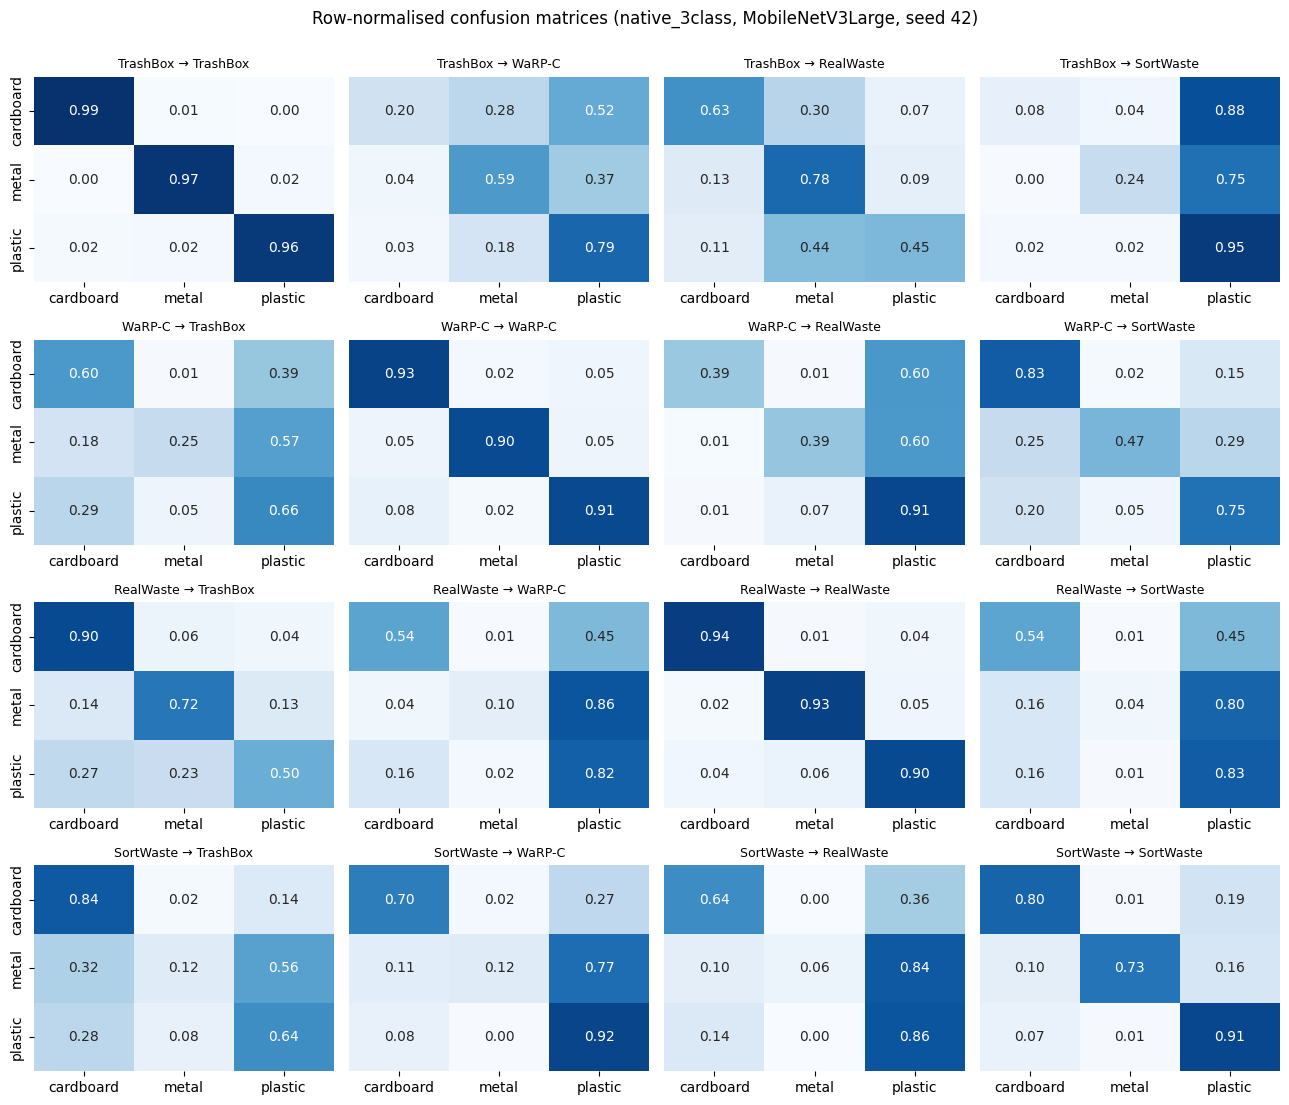

In [ ]:
# Confusion matrices for the main protocol: model trained on each source, tested on every OTHER dataset
main_protocol, main_model, main_seed = "native_3class", RUN_MODELS[0], SEEDS[0]
classes = PROTOCOLS[main_protocol]
fig, axes = plt.subplots(len(DATASETS), len(DATASETS), figsize=(13, 11))
for i, source in enumerate(DATASETS):
    for j, target in enumerate(DATASETS):
        cm = confusions[(main_protocol, main_model, main_seed, source, target)]
        row_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
        sns.heatmap(row_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
                    xticklabels=classes, yticklabels=classes if j == 0 else False, ax=axes[i, j])
        axes[i, j].set_title(f"{source} → {target}", fontsize=9)
plt.suptitle(f"Row-normalised confusion matrices ({main_protocol}, {main_model}, seed {main_seed})", y=1.0)
plt.tight_layout()
save_fig(fig, "confusion_matrices_main")
plt.show()

## 🌪️ Step 9 — Robustness to real-world corruptions
The model trained on `ROBUSTNESS_SOURCE` (main protocol, first seed) is tested on all four datasets, clean and with six synthetic corruptions at three severities
(brightness, blur, noise, rotation, occlusion, scale). `absolute_drop` = clean macro-F1 − corrupted macro-F1 (positive = the corruption hurts).

severity,1,2,3
corruption,,,
blur,-0.005,0.083,0.130
brightness,-0.002,0.009,0.004
noise,0.030,0.096,0.204
occlusion,-0.010,-0.007,0.004
rotation,0.007,0.010,0.007
scale,0.005,0.027,0.099


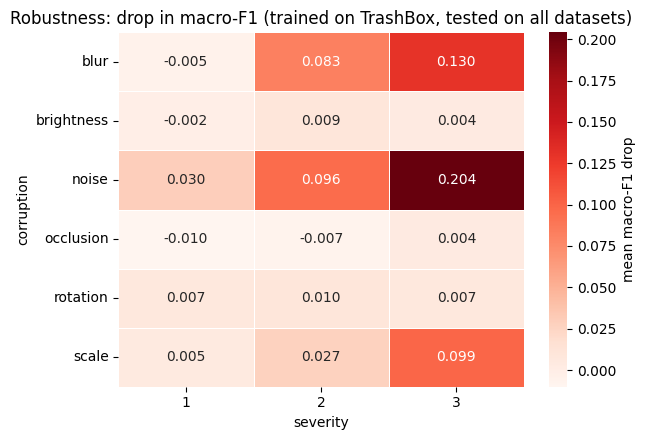

In [ ]:
def corrupt_image(image, corruption, severity, seed):
    rng = random.Random(seed)
    level = severity - 1
    if corruption == "brightness":
        return ImageEnhance.Brightness(image).enhance([0.75, 0.55, 0.35][level])
    if corruption == "blur":
        return image.filter(ImageFilter.GaussianBlur([1.0, 2.0, 3.0][level]))
    if corruption == "rotation":
        return image.rotate([10, 20, 35][level], resample=Image.Resampling.BILINEAR)
    if corruption == "occlusion":
        output = image.copy()
        fraction = [0.12, 0.22, 0.32][level]
        width, height = output.size
        box_w, box_h = int(width * fraction), int(height * fraction)
        x = rng.randrange(max(width - box_w + 1, 1))
        y = rng.randrange(max(height - box_h + 1, 1))
        ImageDraw.Draw(output).rectangle((x, y, x + box_w, y + box_h), fill=(32, 32, 32))
        return output
    if corruption == "scale":
        ratio = [0.75, 0.55, 0.35][level]
        width, height = image.size
        small = image.resize((max(1, int(width * ratio)), max(1, int(height * ratio))))
        output = Image.new("RGB", image.size, (128, 128, 128))
        output.paste(small, ((width - small.width) // 2, (height - small.height) // 2))
        return output
    if corruption == "noise":
        array = np.asarray(image).astype(np.float32)
        sigma = [12, 24, 40][level]
        noise = np.random.default_rng(seed).normal(0, sigma, array.shape)
        return Image.fromarray(np.uint8(np.clip(array + noise, 0, 255)))
    raise ValueError(f"Unknown corruption: {corruption}")

class CorruptedWasteDataset(WasteDataset):
    def __init__(self, paths, classes, corruption, severity, seed):
        super().__init__(paths, classes, transform=None)
        self.corruption, self.severity, self.seed = corruption, severity, seed

    def __getitem__(self, index):
        path, target = self.samples[index]
        image = corrupt_image(load_rgb(path), self.corruption, self.severity, self.seed + index)
        return eval_transform(image), target

def macro_f1_of(model, dataset, k):
    y_true, y_pred = predict(model, make_loader(dataset))
    return macro_f1_from_cm(confusion(y_true, y_pred, k))

rob_protocol, rob_model_name, rob_seed = "native_3class", RUN_MODELS[0], SEEDS[0]
rob_classes = PROTOCOLS[rob_protocol]
rob_model = model_from_state(rob_model_name, rob_classes, STATES[(rob_protocol, rob_model_name, ROBUSTNESS_SOURCE)])
CORRUPTIONS = ["brightness", "blur", "noise", "rotation", "occlusion", "scale"]
rob_rows = []
for target in DATASETS:
    paths = sample_per_class(filtered_paths[(target, "test")], rob_classes, ROB_PER_CLASS, 7000 + DATASETS.index(target))
    clean_f1 = macro_f1_of(rob_model, WasteDataset(paths, rob_classes, eval_transform), len(rob_classes))
    for corruption in CORRUPTIONS:
        for severity in (1, 2, 3):
            data = CorruptedWasteDataset(paths, rob_classes, corruption, severity, seed=100 * severity + DATASETS.index(target))
            score = macro_f1_of(rob_model, data, len(rob_classes))
            rob_rows.append({"train_dataset": ROBUSTNESS_SOURCE, "test_dataset": target, "corruption": corruption,
                             "severity": severity, "n_images": len(paths), "clean_macro_f1": clean_f1,
                             "corrupted_macro_f1": score, "absolute_drop": clean_f1 - score})
robustness = pd.DataFrame(rob_rows)
robust_summary = robustness.groupby(["corruption", "severity"])["absolute_drop"].mean().reset_index(name="mean_macro_f1_drop")
display(robust_summary.pivot(index="corruption", columns="severity", values="mean_macro_f1_drop").round(3))

pivot = robustness.pivot_table(values="absolute_drop", index="corruption", columns="severity", aggfunc="mean")
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="Reds", linewidths=0.5, cbar_kws={"label": "mean macro-F1 drop"}, ax=ax)
ax.set_title(f"Robustness: drop in macro-F1 (trained on {ROBUSTNESS_SOURCE}, tested on all datasets)")
plt.tight_layout()
save_fig(fig, "robustness_heatmap")
plt.show()
del rob_model
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

## 🔬 Step 10 — Ablation (same source, same seed, same evaluation as the main experiment)
`A_baseline` is the main-experiment model itself (no retraining, so it is guaranteed comparable). Variants switch off one ingredient at a time:
no class weights, no augmentation, frozen backbone (only the classifier head is trained).

In [ ]:
abl_protocol, abl_model_name, abl_seed = "native_3class", RUN_MODELS[0], SEEDS[0]
abl_classes = PROTOCOLS[abl_protocol]
abl_rows = []

base = results[(results.protocol == abl_protocol) & (results.model == abl_model_name) &
               (results.seed == abl_seed) & (results.train_dataset == ROBUSTNESS_SOURCE)]
for _, r in base.iterrows():
    abl_rows.append({"variant": "A_baseline", **{k: r[k] for k in ["test_dataset", "in_domain", "n_test",
                     "accuracy", "balanced_accuracy", "macro_f1"]}})

variants = [("B_no_class_weights", dict(use_weights=False)),
            ("C_no_augmentation", dict(use_aug=False)),
            ("D_frozen_backbone", dict(freeze=True))]
for variant, kwargs in variants:
    print(f"\n=== ablation {variant} ===")
    model, record, history = get_or_train(abl_model_name, ROBUSTNESS_SOURCE, abl_protocol, abl_seed, tag=variant, **kwargs)
    model.eval()
    for target in DATASETS:
        row, _ = evaluate_on(model, target, abl_classes, seed=abl_seed * 100 + DATASETS.index(target))
        abl_rows.append({"variant": variant, "test_dataset": target, "in_domain": target == ROBUSTNESS_SOURCE,
                         **{k: row[k] for k in ["n_test", "accuracy", "balanced_accuracy", "macro_f1"]}})
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

ablation = pd.DataFrame(abl_rows)
ablation_summary = (ablation.assign(scope=np.where(ablation.in_domain, "in_domain", "cross_dataset"))
                    .pivot_table(index="variant", columns="scope", values="macro_f1", aggfunc="mean").round(3))
print("Mean macro-F1 per variant (in-domain vs the three other datasets):")
display(ablation_summary)
display(ablation.round(3))


=== ablation B_no_class_weights ===


B_no_class_weights|MobileNetV3Large|TrashBox|ep1:   0%|          | 0/184 [00:00<?, ?it/s]

  MobileNetV3Large | TrashBox | epoch 1: loss=0.3084 val macro-F1=0.9487


B_no_class_weights|MobileNetV3Large|TrashBox|ep2:   0%|          | 0/184 [00:00<?, ?it/s]

  MobileNetV3Large | TrashBox | epoch 2: loss=0.1535 val macro-F1=0.9687


...

  MobileNetV3Large | TrashBox | epoch 4: loss=0.0722 val macro-F1=0.9750


D_frozen_backbone|MobileNetV3Large|TrashBox|ep5:   0%|          | 0/184 [00:00<?, ?it/s]

  MobileNetV3Large | TrashBox | epoch 5: loss=0.0597 val macro-F1=0.9751
Mean macro-F1 per variant (in-domain vs the three other datasets):


scope,cross_dataset,in_domain
variant,,
A_baseline,0.485,0.974
B_no_class_weights,0.480,0.980
C_no_augmentation,0.480,0.957
D_frozen_backbone,0.473,0.971


,variant,test_dataset,in_domain,n_test,accuracy,balanced_accuracy,macro_f1
0,A_baseline,TrashBox,True,774,0.974,0.975,0.974
1,A_baseline,WaRP-C,False,1465,0.713,0.527,0.463
2,A_baseline,RealWaste,False,328,0.610,0.621,0.607
3,A_baseline,SortWaste,False,12618,0.719,0.427,0.386
4,B_no_class_weights,TrashBox,True,774,0.979,0.980,0.980
5,B_no_class_weights,WaRP-C,False,1465,0.784,0.483,0.475
6,B_no_class_weights,RealWaste,False,328,0.643,0.604,0.624
7,B_no_class_weights,SortWaste,False,12618,0.712,0.398,0.340
8,C_no_augmentation,TrashBox,True,774,0.956,0.956,0.957
9,C_no_augmentation,WaRP-C,False,1465,0.757,0.499,0.425


## 👁️ Step 11 — Grad-CAM: where does the model look?
Uses the model trained on `ROBUSTNESS_SOURCE`, tested on the test set of another dataset. Shows up to 3 correctly classified and 3 misclassified images
(the heat map highlights the image regions that pushed the model towards its predicted class).

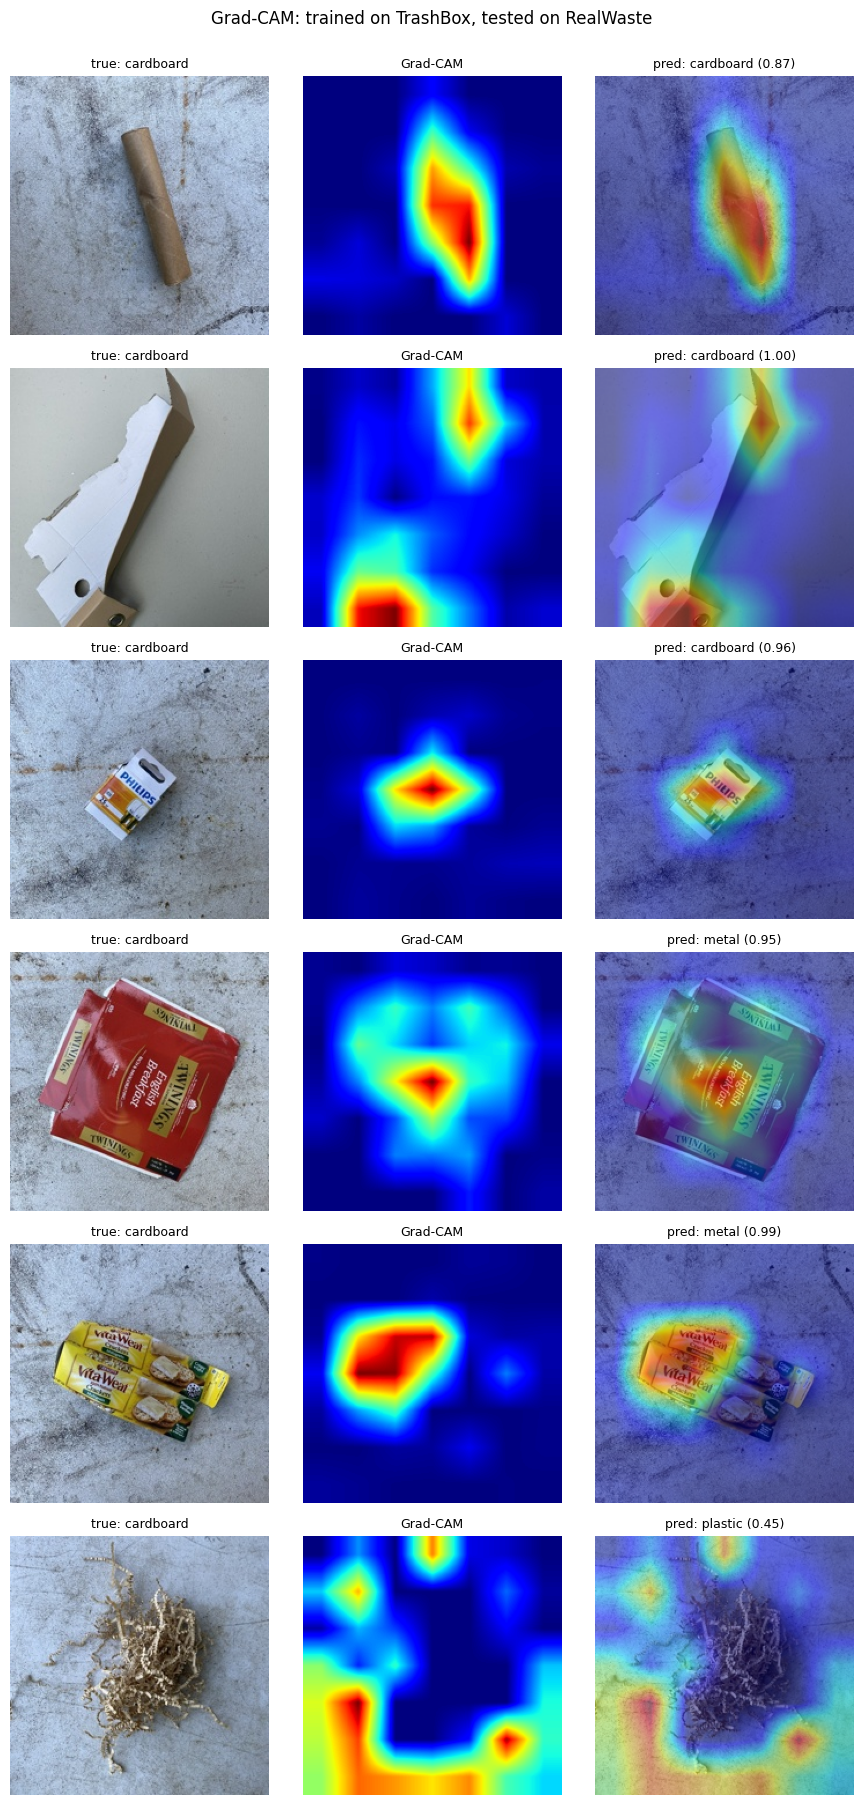

,image,true,predicted,confidence,correct
0,Cardboard_103_2f569cc98b16.jpg,cardboard,cardboard,0.871425,True
1,Cardboard_112_812890d0697e.jpg,cardboard,cardboard,0.999989,True
2,Cardboard_114_91472c83f11e.jpg,cardboard,cardboard,0.962259,True
3,Cardboard_111_c1299d43069d.jpg,cardboard,metal,0.946457,False
4,Cardboard_120_88a408cb6b21.jpg,cardboard,metal,0.988955,False
5,Cardboard_137_9be244390927.jpg,cardboard,plastic,0.452878,False


In [ ]:
def cam_layer(model, model_name):
    return model.layer4[-1] if model_name == "ResNet50" else model.features[-1]

def gradcam_single(model, model_name, tensor):
    model.eval()
    store = {}
    handle = cam_layer(model, model_name).register_forward_hook(lambda m, i, o: store.__setitem__("act", o))
    logits = model(tensor.unsqueeze(0).to(DEVICE))
    handle.remove()
    probs = logits.softmax(dim=1)[0]
    pred = int(probs.argmax())
    act = store["act"]
    grad = torch.autograd.grad(logits[0, pred], act)[0]
    weights = grad.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * act).sum(dim=1, keepdim=True))
    cam = torch.nn.functional.interpolate(cam, size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear", align_corners=False)[0, 0]
    cam = cam.detach().cpu().numpy()
    cam = cam / max(float(cam.max()), 1e-8)
    return pred, float(probs[pred].item()), cam

cam_protocol, cam_model_name = "native_3class", RUN_MODELS[0]
cam_classes = PROTOCOLS[cam_protocol]
cam_target = "RealWaste" if ROBUSTNESS_SOURCE != "RealWaste" else "TrashBox"
cam_model = model_from_state(cam_model_name, cam_classes, STATES[(cam_protocol, cam_model_name, ROBUSTNESS_SOURCE)])

pool = sample_per_class(filtered_paths[(cam_target, "test")], cam_classes, CAM_POOL_PER_CLASS, 99)
pool_data = WasteDataset(pool, cam_classes, eval_transform)
y_true, y_pred = predict(cam_model, make_loader(pool_data))
correct_idx = [i for i in range(len(y_true)) if y_true[i] == y_pred[i]][:3]
wrong_idx = [i for i in range(len(y_true)) if y_true[i] != y_pred[i]][:3]
chosen = correct_idx + wrong_idx

cam_rows = []
if chosen:
    fig, axes = plt.subplots(len(chosen), 3, figsize=(9, 3 * len(chosen)), squeeze=False)
    for r, idx in enumerate(chosen):
        path, truth = pool_data.samples[idx]
        original = load_rgb(path).resize((IMAGE_SIZE, IMAGE_SIZE))
        pred, confidence, cam = gradcam_single(cam_model, cam_model_name, eval_transform(load_rgb(path)))
        overlay = np.uint8(255 * (0.55 * np.asarray(original).astype(float) / 255 + 0.45 * plt.get_cmap("jet")(cam)[..., :3]))
        axes[r, 0].imshow(original); axes[r, 0].set_title(f"true: {cam_classes[truth]}", fontsize=9)
        axes[r, 1].imshow(cam, cmap="jet"); axes[r, 1].set_title("Grad-CAM", fontsize=9)
        axes[r, 2].imshow(overlay); axes[r, 2].set_title(f"pred: {cam_classes[pred]} ({confidence:.2f})", fontsize=9)
        for ax in axes[r]:
            ax.axis("off")
        cam_rows.append({"image": path.name, "true": cam_classes[truth], "predicted": cam_classes[pred],
                         "confidence": confidence, "correct": pred == truth})
    plt.suptitle(f"Grad-CAM: trained on {ROBUSTNESS_SOURCE}, tested on {cam_target}", y=1.0)
    plt.tight_layout()
    save_fig(fig, "gradcam_examples")
    plt.show()
    display(pd.DataFrame(cam_rows))
else:
    print("No images selected for Grad-CAM.")
del cam_model
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

## ⏱️ Step 12 — Efficiency: size and speed
Latency is measured in fp32 on random tensors (so the image decoding speed of Colab's few CPUs does not distort the number): batch size 1 for latency, batch size 32 for throughput.

In [ ]:
def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

def profile_model(model_name, num_classes=3, iters=50):
    model = build_model(model_name, num_classes, pretrained=False).to(DEVICE).eval()
    n_params = sum(p.numel() for p in model.parameters())
    size_mb = sum(t.numel() * t.element_size() for t in model.state_dict().values()) / 1024 ** 2
    one = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
    many = torch.randn(32, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
    with torch.no_grad():
        for _ in range(10):
            model(one)
        sync()
        t0 = time.perf_counter()
        for _ in range(iters):
            model(one)
        sync()
        latency_ms = 1000 * (time.perf_counter() - t0) / iters
        for _ in range(3):
            model(many)
        sync()
        t0 = time.perf_counter()
        for _ in range(iters // 5 + 1):
            model(many)
        sync()
        throughput = 32 * (iters // 5 + 1) / (time.perf_counter() - t0)
    del model
    return {"model": model_name, "parameters_millions": n_params / 1e6, "weights_MB": size_mb,
            "latency_ms_batch1": latency_ms, "throughput_img_per_s_batch32": throughput,
            "device": str(DEVICE)}

efficiency = pd.DataFrame([profile_model(m) for m in RUN_MODELS])
mean_train = training_summary.groupby("model")["training_seconds"].mean().rename("mean_training_seconds_per_model")
efficiency = efficiency.merge(mean_train, left_on="model", right_index=True, how="left")
display(efficiency.round(3))

,model,parameters_millions,weights_MB,latency_ms_batch1,throughput_img_per_s_batch32,device,mean_training_seconds_per_model
0,MobileNetV3Large,4.206,16.138,6.13,1282.608,cuda,172.493


## 💾 Step 13 — Save everything to Google Drive

In [ ]:
results.to_csv(RESULTS_DIR / "results_all_runs.csv", index=False)
agg.to_csv(RESULTS_DIR / "results_matrix_mean_std.csv", index=False)
gap_table.to_csv(RESULTS_DIR / "generalization_gap.csv", index=False)
per_class.to_csv(RESULTS_DIR / "per_class_recall_cross_dataset.csv")
training_summary.drop(columns=["train_class_counts", "classes"]).to_csv(RESULTS_DIR / "training_summary.csv", index=False)
pd.DataFrame(train_histories).to_csv(RESULTS_DIR / "training_histories.csv", index=False)
robustness.to_csv(RESULTS_DIR / "robustness.csv", index=False)
ablation.to_csv(RESULTS_DIR / "ablation.csv", index=False)
efficiency.to_csv(RESULTS_DIR / "efficiency.csv", index=False)
leakage_audit.to_csv(RESULTS_DIR / "leakage_audit.csv", index=False)
native_inventory.to_csv(RESULTS_DIR / "inventory_original.csv", index=False)
study_inventory.to_csv(RESULTS_DIR / "inventory_study.csv", index=False)

metadata = {
    "run_mode": RUN_MODE,
    "valid_for_publication": RUN_MODE == "full",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "device": str(DEVICE), "seeds": SEEDS, "datasets": DATASETS, "classes": CLASS_NAMES,
    "protocols": PROTOCOLS, "models": RUN_MODELS,
    "max_train_per_class": MAX_TRAIN_PER_CLASS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
    "image_size": IMAGE_SIZE, "batch_size": BATCH_SIZE, "bootstrap_resamples": N_BOOTSTRAP,
    "checkpoint_selection": "macro-F1 on the SOURCE validation split only",
    "software": {"python": sys.version, "platform": platform.platform(), "torch": torch.__version__,
                 "torchvision": torchvision.__version__, "numpy": np.__version__,
                 "pandas": pd.__version__, "scikit_learn": sklearn.__version__},
    "citations": [
        "TrashBox: Kumsetty et al., TrashBox: Trash Detection and Classification using Quantum Transfer Learning, FRUCT 2022, doi:10.23919/FRUCT54823.2022.9770922",
        "WaRP: Yudin et al., Hierarchical waste detection with weakly supervised segmentation in images from recycling plants, Engineering Applications of Artificial Intelligence 128 (2024) 107542, doi:10.1016/j.engappai.2023.107542",
        "RealWaste: UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/908/realwaste",
        "Auxiliary glass/paper images: Kaggle zlatan599/garbage-dataset-classification (verify licence and cite the dataset owner)",
        "SortWaste: cite the original source/repository that came with the downloaded archive; verify its publication and licence before publishing",
    ],
}
(RESULTS_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2, default=str))

limitations = [
    "supplemented_5class: the glass/paper images in WaRP-C and SortWaste come from a different source, so a model can use image style as a shortcut for those classes. Treat native_3class as the main result.",
    "native_3class uses only cardboard, metal and plastic, the three classes present in all four original datasets.",
    "WaRP-C and SortWaste are dominated by plastic; the per-class cap and class-weighted loss reduce, but do not remove, the imbalance. Report macro-F1 and per-class recall, not accuracy.",
    "SHA-256 only detects byte-identical files. Near-duplicate frames from the same conveyor video (WaRP, SortWaste) can still sit in both train and test and inflate in-domain scores.",
    "Bootstrap intervals resample images, not objects, videos or sites, so they are optimistic.",
    "Only one backbone family and 3 seeds by default; WaRP original classes were mapped into 5 material classes (document the mapping in the paper).",
    "Smoke-mode results are meaningless; only RUN_MODE='full' outputs may be reported.",
]
display(pd.DataFrame({"Limitations": limitations}))
print(f"\nSaved results, figures, checkpoints and metadata to: {RESULTS_DIR}")
if RUN_MODE == "smoke":
    print("Smoke run finished without errors. Now set RUN_MODE = 'full' and use Runtime > Restart session and run all.")

,Limitations
0,supplemented_5class: the glass/paper images in...
1,"native_3class uses only cardboard, metal and p..."
2,WaRP-C and SortWaste are dominated by plastic;...
3,SHA-256 only detects byte-identical files. Nea...
4,"Bootstrap intervals resample images, not objec..."
5,Only one backbone family and 3 seeds by defaul...
6,Smoke-mode results are meaningless; only RUN_M...



Saved results, figures, checkpoints and metadata to: /content/drive/MyDrive/industrial_waste_results/full


## 🧾 Step 14 — Quick interpretation helper
Prints the strongest and weakest cross-dataset transfers for the main protocol, so you know what to discuss in the paper.

In [ ]:
main = agg[(agg.protocol == "native_3class") & (agg.model == RUN_MODELS[0]) & (agg.train_dataset != agg.test_dataset)]
best = main.sort_values("mean", ascending=False).head(3)
worst = main.sort_values("mean").head(3)
print("Best transfers (train → test, macro-F1):")
for _, r in best.iterrows():
    print(f"  {r.train_dataset} → {r.test_dataset}: {r['mean']:.3f}")
print("Worst transfers:")
for _, r in worst.iterrows():
    print(f"  {r.train_dataset} → {r.test_dataset}: {r['mean']:.3f}")
worst_gap = gap_table[(gap_table.protocol == "native_3class")].sort_values("generalization_gap", ascending=False).iloc[0]
print(f"\nLargest generalization gap: model trained on {worst_gap.train_dataset} "
      f"(in-domain {worst_gap.in_domain_macro_f1:.3f} vs cross-dataset {worst_gap.cross_dataset_macro_f1:.3f}).")
if RUN_MODE == "smoke":
    print("\n(Smoke mode: ignore these numbers.)")

Best transfers (train → test, macro-F1):
  RealWaste → TrashBox: 0.686
  TrashBox → RealWaste: 0.642
  WaRP-C → RealWaste: 0.563
Worst transfers:
  TrashBox → SortWaste: 0.376
  RealWaste → WaRP-C: 0.451
  RealWaste → SortWaste: 0.468

Largest generalization gap: model trained on TrashBox (in-domain 0.981 vs cross-dataset 0.499).
